In [1]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [2]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [3]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random
from scipy.stats import norm

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder as skTE
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')
pd.set_option("display.max_columns", 100)
# sns.set_style("whitegrid")

In [4]:
!uv pip install -q -U bartz

In [5]:
from bartz.BART import gbart, mc_gbart

!pip show bartz

Name: bartz
Version: 0.14.0
Summary: Super-fast BART (Bayesian Additive Regression Trees) in Python
Home-page: https://github.com/bartz-org/bartz
Author: 
Author-email: Giacomo Petrillo <info@giacomopetrillo.com>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: equinox, jax, jaxtyping, numpy, scipy, tqdm, typing-extensions
Required-by: 


In [6]:
!uv pip install -q bartz[cuda13]

In [7]:
## -- Tell JAX to use all and only 95% of the GPU memory
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = '.95'

print("📥 Memory limited to 95% usage")

📥 Memory limited to 95% usage


In [8]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [9]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

## =================================================================================

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

Mounted at /content/drive
Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


## FEATURE ENGINEERING

In [10]:
ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

# del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
important_combos = [
    ('merchant_category', 'card_type', 'txn_count_last_24h'),
    ('merchant_category', 'customer_age'),
]
def feature_engineering(df, fit=False):
    # Digit extraction
    for col in ['amount_usd', 'hours_since_last_txn',
                'velocity_score', 'distance_from_home_km']:
        decimal_name = f"_{col}_decimal"
        df[decimal_name] = (df[col] % 1).round(2).astype('float32')

    # Categorize numericals
    for col in num_cols + ['_amount_usd_decimal', '_hours_since_last_txn_decimal',
                           '_velocity_score_decimal', '_distance_from_home_km_decimal']:
        cat_name = f"{col}_cat_" if col in num_cols else f"{col[1:]}_cat_"
        values = np.floor(df[col]) if col in num_cols else df[col]
        if fit:
            codes, uniques = values.factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = values.map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    # Discretize numericals
    bin_config = {'merchant_risk_score': [7], 'hours_since_last_txn': [500, 1000]}
    for col, bins_list in bin_config.items():
        for n_bins in bins_list:
            for strategy in ['quantile']:
                bin_name = f"{col}_{n_bins}_{strategy}_bin_"
                if fit:
                    kb = KBinsDiscretizer(
                        n_bins=n_bins,
                        encode='ordinal',
                        strategy=strategy,
                        subsample=None
                    )
                    binned = kb.fit_transform(df[[col]]).ravel().astype('int32')
                    category_map[bin_name] = kb
                else:
                    kb = category_map[bin_name]
                    binned = kb.transform(df[[col]]).ravel().astype('int32')
                df[bin_name] = binned
                df[bin_name] = df[bin_name].astype('category')

    # Create interaction categories
    combo_names = []
    for cols in important_combos:
        combo_name = '_'.join(cols) + '_'
        combo_names.append(combo_name)
        combo_series = df[cols[0]].astype(str)
        for col in cols[1:]:
            combo_series = combo_series + '_' + df[col].astype(str)
        if fit:
            codes, uniques = pd.factorize(combo_series, sort=False)
            category_map[combo_name] = uniques
        else:
            uniques = category_map[combo_name]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = combo_series.map(code_map).fillna(-1).astype('int32')
        df[combo_name] = codes
        df[combo_name] = df[combo_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols, combo_names

X, new_cat_cols, new_num_cols, combo_names = feature_engineering(X, fit=True)
X_test, _, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape)
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 22
len(new_num_cols): 4 

prep len(cat_cols): 33
prep len(num_cols): 17 

X      prep shape: (699960, 50)
X_test prep shape: (299984, 50)
----------------------------------------


In [11]:
X.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,_distance_from_home_km_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.16,0.77,0.5,0.78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.83,0.54,0.4,0.06,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.36,0.20,0.8,0.17,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.44,0.13,0.7,0.67,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.85,0.80,0.8,0.69,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4


# ML TRAINING

In [12]:
# USE_FULL_TRAIN = True

# x_sample, x_sample2 = train_test_split(
#     train,
#     train_size=50_000,
#     stratify=train[TARGET],
#     random_state=42
# )

# train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
# print(train_X.shape, type(train_X))

# FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

# print(f"Train shape {train_X.shape}")
# # train_X.head()

In [13]:
# ## -- Handle optional original table aggregations
# USE_ORIGINAL = True

# import_cols = base_cols

# if USE_ORIGINAL:
#     aggs_ = ["count"]  # "mean", "count", "std", "skew", "nunique",
#     feats = FEATURES.copy()
#     x_train, orig_cols = original_obTE(
#         orig, train_X, target=TARGET, features = import_cols,
#         aggs=aggs_, fill_nan=True
#     )
#     x_test, _ = original_obTE(
#         orig, test, target=TARGET, features = import_cols,
#         aggs=aggs_, fill_nan=True
#     )
#     feats.extend(orig_cols)
#     X = x_train[feats]
#     X_test = x_test[feats]
#     y = train_X[TARGET].astype("int8")
# else:
#     X = train_X[FEATURES]
#     X_test = test[FEATURES]
#     y = train_X[TARGET].astype("int8")

# print(X.shape, type(X))
# X.head()

In [14]:
# corr_type = ['pearson', 'spearman'][0]

# plt.figure(figsize=(15, 4))
# corr_df = X.corrwith(train_X[TARGET], method=corr_type)
# corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
# for i, v in enumerate(corr_df.values):
#     plt.text(
#         i, np.abs(v) + 0.001, np.round(v, 3),
#         size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
#         va='bottom', ha='center',
#     )

# plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
# plt.show()

In [15]:
## -- Reduce data memory --

def reduce_memory(df, factorize_first=False):
    # Use copy() if you want to avoid modifying the original dataframe in place
    # df = df.copy()

    old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

    for c in tqdm(df.columns, desc='Reducing memory...'):
        col_type = df[c].dtype

        # If it is already a category, we don't need to reduce it further
        if isinstance(col_type, pd.CategoricalDtype):
            continue

        # Check if type is bool (True or False)
        if col_type == bool:
            if factorize_first:
                df[c], _ = df[c].factorize(sort=True)
                df[c] = df[c].astype('category')
            else:
                df[c] = df[c].astype(str).astype('category')
        # Check if type is integer
        elif np.issubdtype(col_type, np.integer):
            df[c] = pd.to_numeric(df[c], downcast='integer')
        # Optional: Convert object types with low cardinality to category
        elif col_type == object:
            if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
                if factorize_first:
                    df[c], _ = df[c].factorize(sort=True)
                    df[c] = df[c].astype('category')
                else:
                    df[c] = df[c].astype('category')
        # Check if type is float
        # elif np.issubdtype(col_type, np.floating):
        #     df[c] = pd.to_numeric(df[c], downcast='float')

    new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

    return df

X = reduce_memory(X, factorize_first=True)
X_test = reduce_memory(X_test, factorize_first=True)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

X.head()

Reducing memory...:   0%|          | 0/50 [00:00<?, ?it/s]

Size before process: 292.5 MB
Size after process : 73.7 MB



Reducing memory...:   0%|          | 0/50 [00:00<?, ?it/s]

Size before process: 125.4 MB
Size after process : 31.7 MB

Data memory reduced!


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,_amount_usd_decimal,_hours_since_last_txn_decimal,_velocity_score_decimal,_distance_from_home_km_decimal,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd_decimal_cat_,hours_since_last_txn_decimal_cat_,velocity_score_decimal_cat_,distance_from_home_km_decimal_cat_,merchant_risk_score_7_quantile_bin_,hours_since_last_txn_500_quantile_bin_,hours_since_last_txn_1000_quantile_bin_,merchant_category_card_type_txn_count_last_24h_,merchant_category_customer_age_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,5,2,3,4,7,0,0,0,0,0,0,0.16,0.77,0.5,0.78,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,371,553,0,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,7,4,4,2,1,0,0,0,0,0,0,0.83,0.54,0.4,0.06,1,1,1,1,1,1,1,0,1,1,1,0,1,1,1,1,1,2,80,104,1,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,11,4,3,3,5,0,0,1,0,0,0,0.36,0.20,0.8,0.17,2,1,2,2,2,2,2,0,2,2,2,1,0,2,2,2,2,1,59,79,2,2
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,5,2,0,4,1,0,0,0,0,0,0,0.44,0.13,0.7,0.67,3,2,2,2,0,3,3,0,3,3,0,2,0,3,3,3,3,5,251,338,3,3
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,1,4,0,3,6,0,0,0,0,0,0,0.85,0.80,0.8,0.69,4,3,2,3,3,4,4,0,4,4,3,3,0,4,4,2,4,5,42,54,4,4


In [16]:
# amount_usd_FREQ_train
# 9.0
# 262.0
# 173.0
# 156.0
# 18.0

# amount_usd_FREQ_combined
# 13.0
# 372.0
# 258.0
# 226.0
# 27.0

In [17]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 50 columns):
 #   Column                                           Non-Null Count   Dtype   
---  ------                                           --------------   -----   
 0   amount_usd                                       699960 non-null  float64 
 1   hours_since_last_txn                             699960 non-null  float64 
 2   txn_count_last_24h                               699960 non-null  int8    
 3   distance_from_home_km                            699960 non-null  float64 
 4   card_age_months                                  699960 non-null  int8    
 5   customer_age                                     699960 non-null  int8    
 6   account_balance_usd                              699960 non-null  float64 
 7   cvv_retry_count                                  699960 non-null  int8    
 8   velocity_score                                   699960 non-null  float64 
 9   time

In [31]:
# import jax
# # Attempt to resolve StableHLO/JIT serialization issues by disabling JIT compilation
# # or forcing alternate compilation configurations if necessary.
# jax.config.update("jax_disable_jit", True)

class CFG:
    TE = True if 'combo_names' in globals() else False
    PREDICT_TEST = True
    FOLDS = 5
    SEED = 42

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = 'BARTZp_mlp'
print(f"🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

_bins = [c for c in X.columns if c.endswith('_bin_')]
_cats = [c for c in X.columns if c.endswith('_cat_')]

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = combo_names + _bins + _cats
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 20
        print(f"⚡️ TargetEncoding({len(te_cols)}) • smooth={smooth}", end=" | ")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ----------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    params = {
        "type": 'pbart',
        'ntree':  100, # d=50
        # 'mc_cores': 4, # d=2
        'keepevery': 50, # d=10 ⚡️ -> use 100
        'nskip': 150, # d=100
        # ------------------------
        # 'k': 4.0, # d=2.0
        #'ndpost': 500, # d=1000
        # 'numcut': 255, # d=100
        # ------------------------
        # 'usequants': True,
        #'sparse': True,
        #'augment':True,
        # "seed": 42, # d=0
    }

    seeder = 42 #+ (fold-1)
    params['seed'] = seeder

    model = mc_gbart(
        X_trn,
        y_trn.astype(bool) if params['type']=="pbart" else y_trn.astype('float32'),
        # x_test=X_tst.to_numpy(),
        **params,
    )

    # val_preds = model.predict(X_val).mean(axis=0).ravel()
    val_preds = norm.cdf(model.predict(X_val).mean(axis=0).ravel())
    oof_preds[val_idx] = val_preds

    if CFG.PREDICT_TEST:
        t_ = time()
        print("⧗ test predictions... ", end="")
        # fold_test_preds = model.predict(X_tst).mean(axis=0).ravel()
        fold_test_preds = norm.cdf(model.predict(X_tst).mean(axis=0).ravel())
        test_preds += fold_test_preds
        print(f"{(time()-t_)/60:.2f} min")
    # ----------------------------------------------------------------------------------
    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.ndpost
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed= {seeder}, tree= {best_iter}, time= {ff} mins ]\n")

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"
features_used = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (score, tree, dura) in enumerate(zip(fold_scores, best_iterations, fold_times), 1):
    print(f" • Fold {i} AUC: {score} @ tree {tree} in {dura} mins")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
fold_results[f'tree'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.2f} mins\n")

del X_trn, X_val, y_trn, y_val, model

🚀 Training BARTZp_mlp(50) with 5 Folds

### Fold 1/5
⚡️ TargetEncoding(22) • smooth=10 | train=(559968, 50), valid=(139992, 50)



train   0%|          | 0/25150 [00:00<?, ?it/s]

⧗ test predictions... 0.21 min
# Fold 1 AUC: 0.94941 [ seed= 42, tree= 1000, time= 6.28 mins ]

### Fold 2/5
⚡️ TargetEncoding(22) • smooth=10 | 

train   0%|          | 0/25150 [00:00<?, ?it/s]

⧗ test predictions... 0.21 min
# Fold 2 AUC: 0.95101 [ seed= 42, tree= 1000, time= 6.31 mins ]

### Fold 3/5
⚡️ TargetEncoding(22) • smooth=10 | 

train   0%|          | 0/25150 [00:00<?, ?it/s]

⧗ test predictions... 0.21 min
# Fold 3 AUC: 0.95464 [ seed= 42, tree= 1000, time= 6.32 mins ]

### Fold 4/5
⚡️ TargetEncoding(22) • smooth=10 | 

train   0%|          | 0/25150 [00:00<?, ?it/s]

⧗ test predictions... 0.21 min
# Fold 4 AUC: 0.95075 [ seed= 42, tree= 1000, time= 6.28 mins ]

### Fold 5/5
⚡️ TargetEncoding(22) • smooth=10 | 

train   0%|          | 0/25150 [00:00<?, ?it/s]

⧗ test predictions... 0.21 min
# Fold 5 AUC: 0.94427 [ seed= 42, tree= 1000, time= 6.26 mins ]


5-FOLD CV: BARTZp_mlp(50) | (559968, 50)
 • Fold 1 AUC: 0.94941 @ tree 1000 in 6.28 mins
 • Fold 2 AUC: 0.95101 @ tree 1000 in 6.31 mins
 • Fold 3 AUC: 0.95464 @ tree 1000 in 6.32 mins
 • Fold 4 AUC: 0.95075 @ tree 1000 in 6.28 mins
 • Fold 5 AUC: 0.94427 @ tree 1000 in 6.26 mins
--------------------------------------------------
OOF score: 0.94998
AVG score: 0.95002 ± 0.00336
--------------------------------------------------
31.46 mins



In [26]:
# ==================================================
# 5-FOLD CV: BARTZp_mlp(50) | (559968, 50)
# ==================================================
#  • Fold 1 AUC: 0.94906 @ tree 1000 in 6.29 mins
#  • Fold 2 AUC: 0.95107 @ tree 1000 in 6.31 mins
#  • Fold 3 AUC: 0.95466 @ tree 1000 in 6.3 mins
#  • Fold 4 AUC: 0.95079 @ tree 1000 in 6.27 mins
#  • Fold 5 AUC: 0.94475 @ tree 1000 in 6.22 mins
# --------------------------------------------------
# OOF score: 0.95002
# AVG score: 0.95007 ± 0.00322
# --------------------------------------------------
# 31.40 mins

In [27]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
BARTZp_mlp(50)_95007
-------------------------
31.4 mins



,auc,tree,time(min)
fold 1,0.94906,1000,6.29
fold 2,0.95107,1000,6.31
fold 3,0.95466,1000,6.30
fold 4,0.95079,1000,6.27
fold 5,0.94475,1000,6.22


In [28]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000017
1,699961,0.000002
2,699962,0.087251
3,699963,0.000709
4,699964,0.000367


In [29]:
# !rm -r /kaggle/working

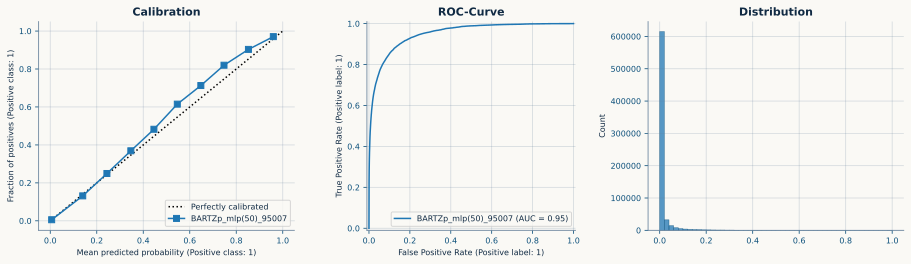

In [30]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 3.5))

# # Convert probit scores to probabilities using Scipy's norm.cdf
# oof_probs = norm.cdf(oof_preds)

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(pad=0.2)
plt.show()

In [ ]:
# ## -- Feature Importances --
# top_n_features = 30

# imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()
# print(f"Total used features: {len(imp_df)}\n")

# ax = imp_df[-top_n_features:].plot.barh(figsize=(12.5, 8))
# ax.set_title(f"{n}: Avg. {FOLDS}-Fold Importances", loc='left')
# ax.grid(True)

# plt.tight_layout()
# plt.show()